# Task 2: Real Estate Housing Price Prediction
## Comparative Evaluation: Ordinary Least Squares (OLS), Ridge, and Lasso Regression
**Datheon Machine Learning & Data Science Internship Suite**

---

### 1. Executive Summary & Problem Formulation
This project models and predicts California district median housing values (`median_house_value`) in USD using the 1990 California Census dataset (20,640 district blocks).

We address key real-world regression challenges:
- **Missing Value Imputation**: Median numerical imputation fitted strictly on the training partition.
- **Categorical Processing**: `ocean_proximity` encoded via `OneHotEncoder(handle_unknown='ignore')`.
- **Feature Interaction Engineering**: Synthesizing ratio metrics (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
- **Multicollinearity Diagnostics**: Correlation analysis and Variance Inflation Factors (VIF).
- **Regularization & Hyperparameter Tuning**: Comparing unregularized OLS against L2 (Ridge) and L1 (Lasso) regularizers tuned via 5-fold cross-validation.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.common.data_loader import load_dataset
from src.common.evaluation import evaluate_regression
from src.common.visualization import plot_model_comparison, plot_regression_diagnostics
from src.regression.housing_pipeline import (
    prepare_housing_data,
    add_interaction_features,
    build_preprocessor,
    train_and_tune_models,
    compute_vif_dataframe,
    plot_correlation_heatmap,
    predict_house_value,
    ALL_NUMERIC_COLS,
    RAW_NUMERIC_COLS,
    CATEGORICAL_COLS,
    TARGET_COL
)

%matplotlib inline


### 2. Dataset Ingestion & Initial Schema Inspection
We load the California Housing dataset using the resilient data loader, cached under `data/raw/housing.csv`.


In [2]:
df_raw, meta = load_dataset('task2_housing')
print(f"Dataset Dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"Data Source Used: {meta['source_used']}")
print("\nMissing values per column:")
print(df_raw.isnull().sum())
df_raw.head()


[INFO] Fetching primary dataset for 'task2_housing' from https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv...


[INFO] Successfully downloaded: https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv -> D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\housing.csv


[INFO] Dataset 'task2_housing' validated: 20640 rows, 10 cols.


Dataset Dimensions: 20640 rows x 10 columns
Data Source Used: primary_url:https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### 3. Exploratory Data Analysis & Target Distribution
Inspection of target variable `median_house_value` and numerical attribute distributions.
Notice the right-skew and the $500,001 artificial ceiling cap present in the 1990 census.


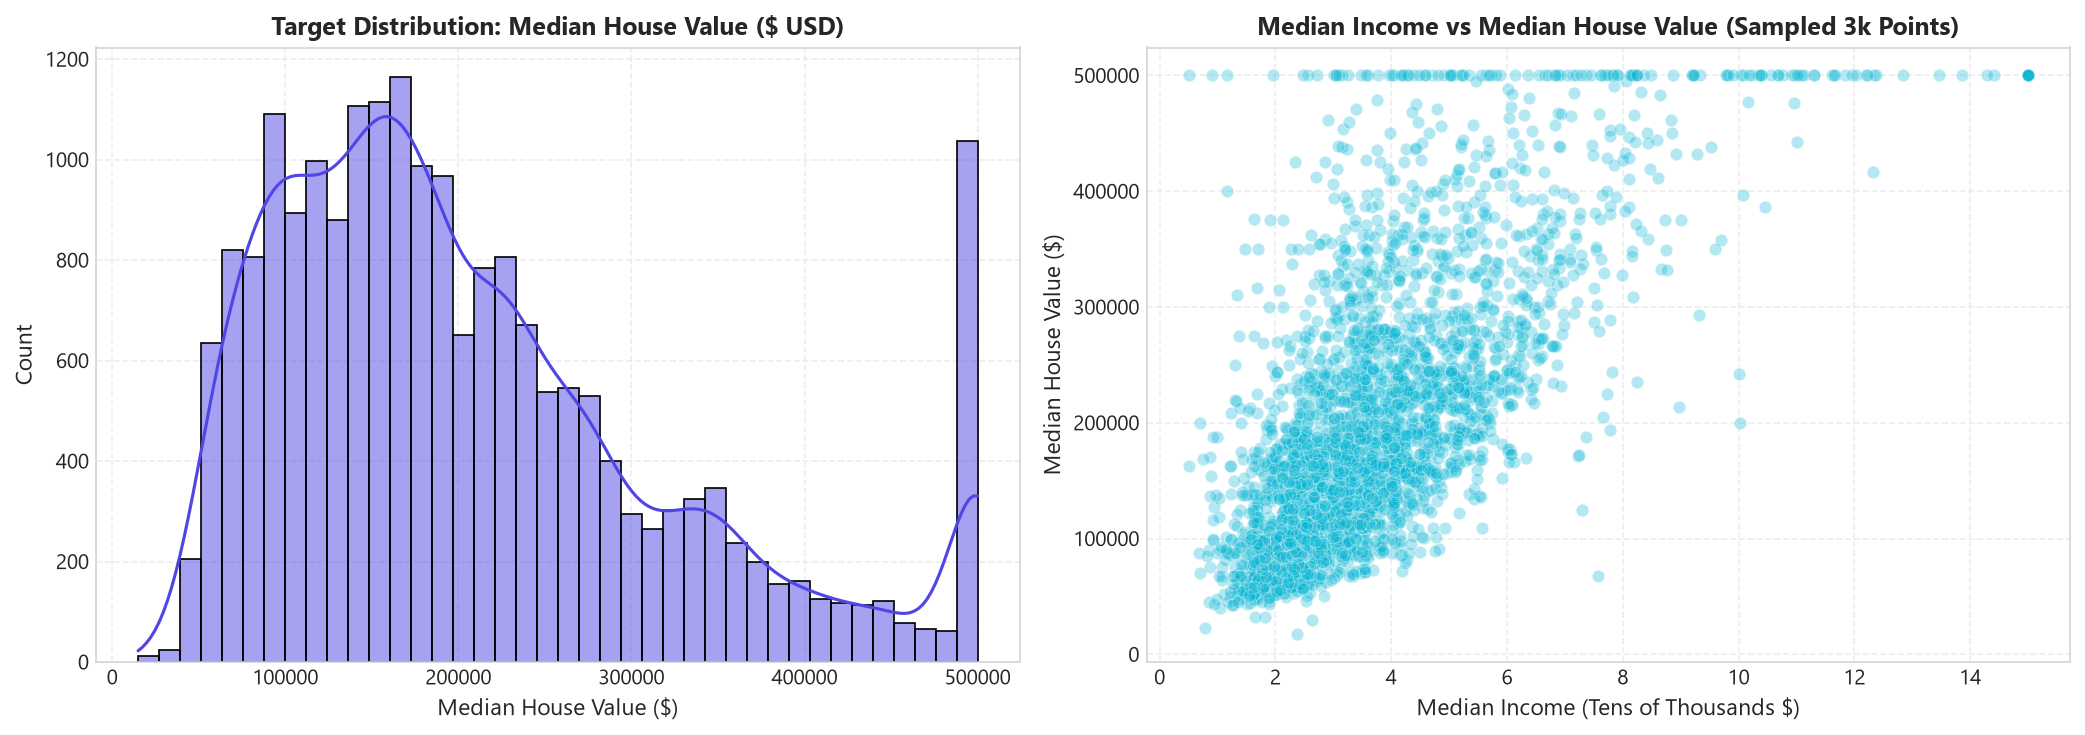

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target distribution
sns.histplot(df_raw[TARGET_COL], kde=True, ax=axes[0], color='#4F46E5', bins=40)
axes[0].set_title('Target Distribution: Median House Value ($ USD)', weight='bold')
axes[0].set_xlabel('Median House Value ($)')

# Median Income vs House Value
sns.scatterplot(
    data=df_raw.sample(3000, random_state=42),
    x='median_income', y=TARGET_COL, alpha=0.3, ax=axes[1], color='#06B6D4'
)
axes[1].set_title('Median Income vs Median House Value (Sampled 3k Points)', weight='bold')
axes[1].set_xlabel('Median Income (Tens of Thousands $)')
axes[1].set_ylabel('Median House Value ($)')

plt.tight_layout()
plt.show()


### 4. Domain Feature Interaction Engineering
Raw room and bedroom aggregates depend heavily on the total block population.
We construct three normalized ratio features:
1. `rooms_per_household = total_rooms / households`
2. `bedrooms_per_room = total_bedrooms / total_rooms`
3. `population_per_household = population / households`


In [4]:
df_engineered = add_interaction_features(df_raw)
df_engineered[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe()


,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20433.000000,20640.000000
mean,5.429000,0.213039,3.070655
std,2.474173,0.057983,10.386050
min,0.846154,0.100000,0.692308
25%,4.440716,0.175427,2.429741
50%,5.229129,0.203162,2.818116
75%,6.052381,0.239821,3.282261
max,141.909091,1.000000,1243.333333


### 5. Multicollinearity Diagnostics: Correlation Heatmap & Variance Inflation Factors (VIF)
We analyze linear dependencies among features. High VIF scores in geographic coordinates (`latitude` / `longitude`) and scale metrics (`total_rooms` / `households`) reflect physical spatial clustering rather than data defects. Regularization (Ridge and Lasso) directly handles this multicollinearity without needing arbitrary feature deletion.


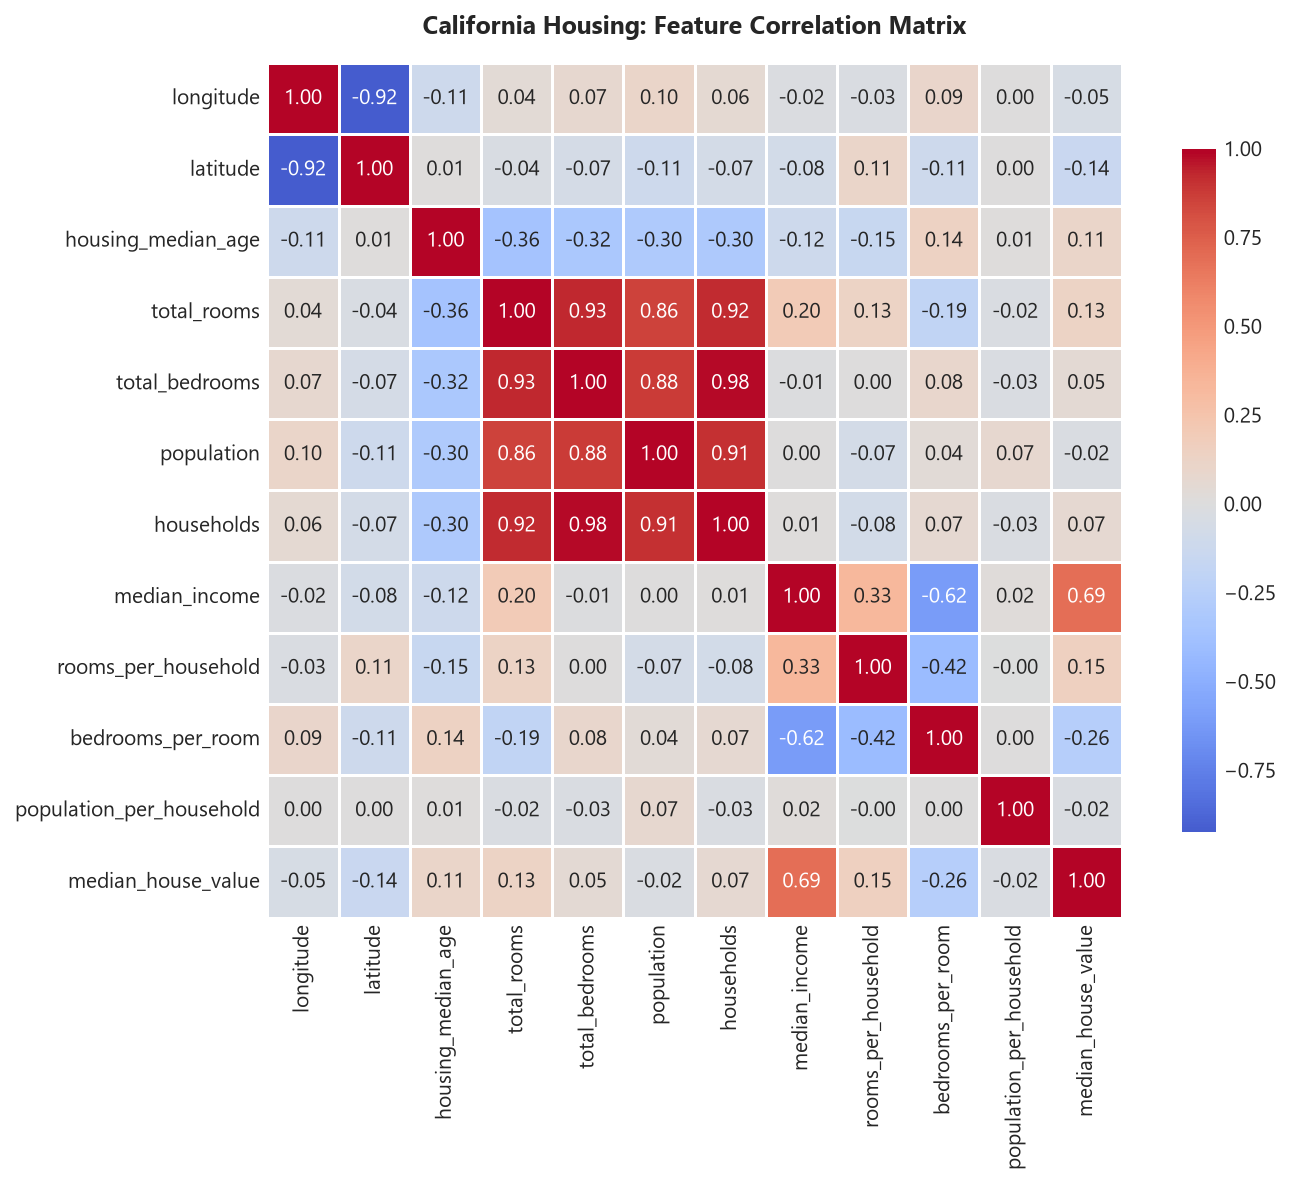

Variance Inflation Factor (VIF) Diagnostic Table:


,feature,vif
0,total_bedrooms,36.003726
1,households,35.136045
2,total_rooms,12.717000
3,latitude,8.828919
4,longitude,8.713740
5,population,6.371238
6,median_income,1.731511
7,housing_median_age,1.260015


In [5]:
fig_corr = plot_correlation_heatmap(df_engineered)
plt.show()

vif_table = compute_vif_dataframe(df_engineered, RAW_NUMERIC_COLS)
print("Variance Inflation Factor (VIF) Diagnostic Table:")
display(vif_table)


### 6. Leakage-Free Preprocessing & Train-Test Partitioning
We split the data (80:20 ratio) *before* fitting imputers, scalers, or one-hot encoders.
`ColumnTransformer` encapsulates:
- Numerical attributes: `SimpleImputer(strategy='median')` -> `StandardScaler()`
- Categorical attributes: `OneHotEncoder(handle_unknown='ignore')`


In [6]:
X_train, X_test, y_train, y_test, _ = prepare_housing_data(random_state=42, test_size=0.2)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")


[INFO] Loading cached dataset for 'task2_housing' from D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\housing.csv


[INFO] Dataset 'task2_housing' validated: 20640 rows, 10 cols.


[INFO] California housing data partitioned: 16512 train rows, 4128 test rows.


X_train shape: (16512, 12)
X_test shape:  (4128, 12)


### 7. Model Training & 5-Fold Cross-Validation Hyperparameter Tuning
We train:
1. **OLS Baseline (`LinearRegression`)**: Unregularized ordinary least squares.
2. **Ridge Regression (L2)**: Regularization strength tuned across `[0.1, 1.0, 10.0, 50.0, 100.0, 200.0]`.
3. **Lasso Regression (L1)**: Regularization strength tuned across `[1.0, 10.0, 50.0, 100.0, 250.0]`.


In [7]:
models, results, predictions = train_and_tune_models(X_train, y_train, X_test, y_test, cv=5)

print("\n=== TEST SET REGRESSION EVALUATION ===")
summary_rows = []
for name, m in results.items():
    summary_rows.append({
        'Model': name.replace('_', ' ').title(),
        'RMSE ($)': f"${m['rmse']:,.2f}",
        'MAE ($)': f"${m['mae']:,.2f}",
        'R² Score': f"{m['r2']:.4f}",
        'Best Alpha': m.get('best_alpha', 'N/A')
    })
display(pd.DataFrame(summary_rows))


[INFO] Fitting OLS Linear Regression baseline...


[INFO] Tuning Ridge regularization strength with 5-fold CV...


[INFO] Tuning Lasso regularization strength with 5-fold CV...


C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.269471e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(
[INFO] ols_linear_regression -> Test RMSE: $69,127.04, MAE: $49,645.49, R²: 0.6353


[INFO] ridge_regression -> Test RMSE: $69,134.97, MAE: $49,652.14, R²: 0.6353


[INFO] lasso_regression -> Test RMSE: $69,128.08, MAE: $49,646.41, R²: 0.6353



=== TEST SET REGRESSION EVALUATION ===


,Model,RMSE ($),MAE ($),R² Score,Best Alpha
0,Ols Linear Regression,"$69,127.04","$49,645.49",0.6353,N/A
1,Ridge Regression,"$69,134.97","$49,652.14",0.6353,1.0
2,Lasso Regression,"$69,128.08","$49,646.41",0.6353,1.0


### 8. Regression Residual Diagnostics
We inspect Actual vs Predicted scatter plots, Residual vs Predicted plots, and error distributions to detect non-linearity and heteroscedasticity.


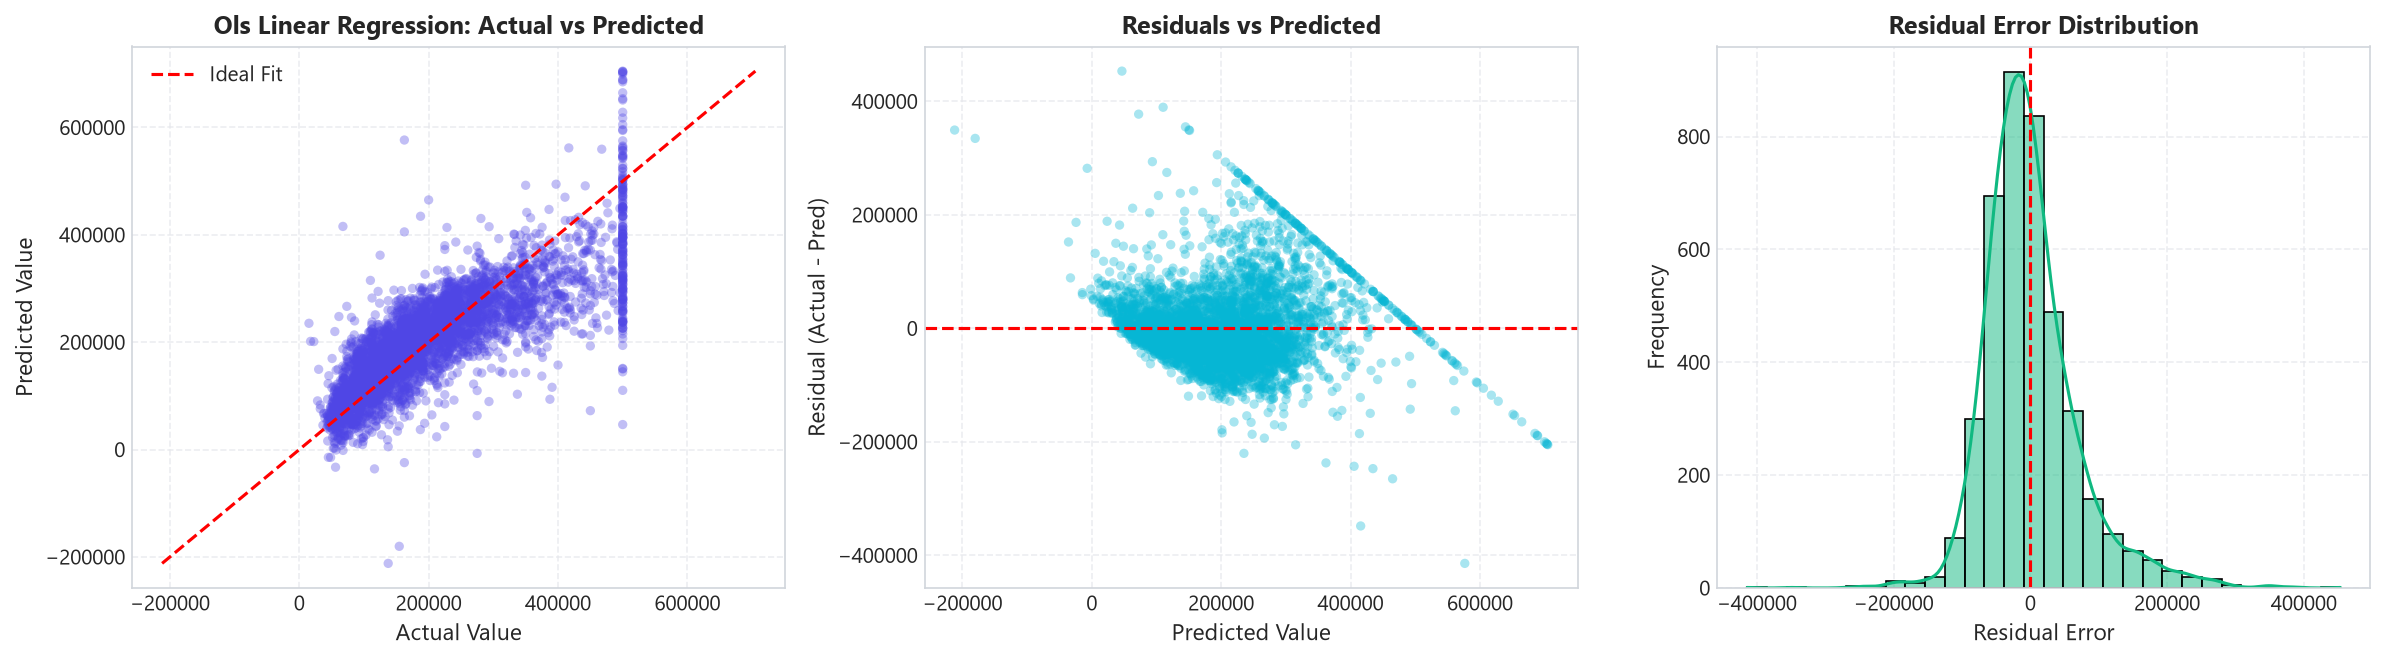

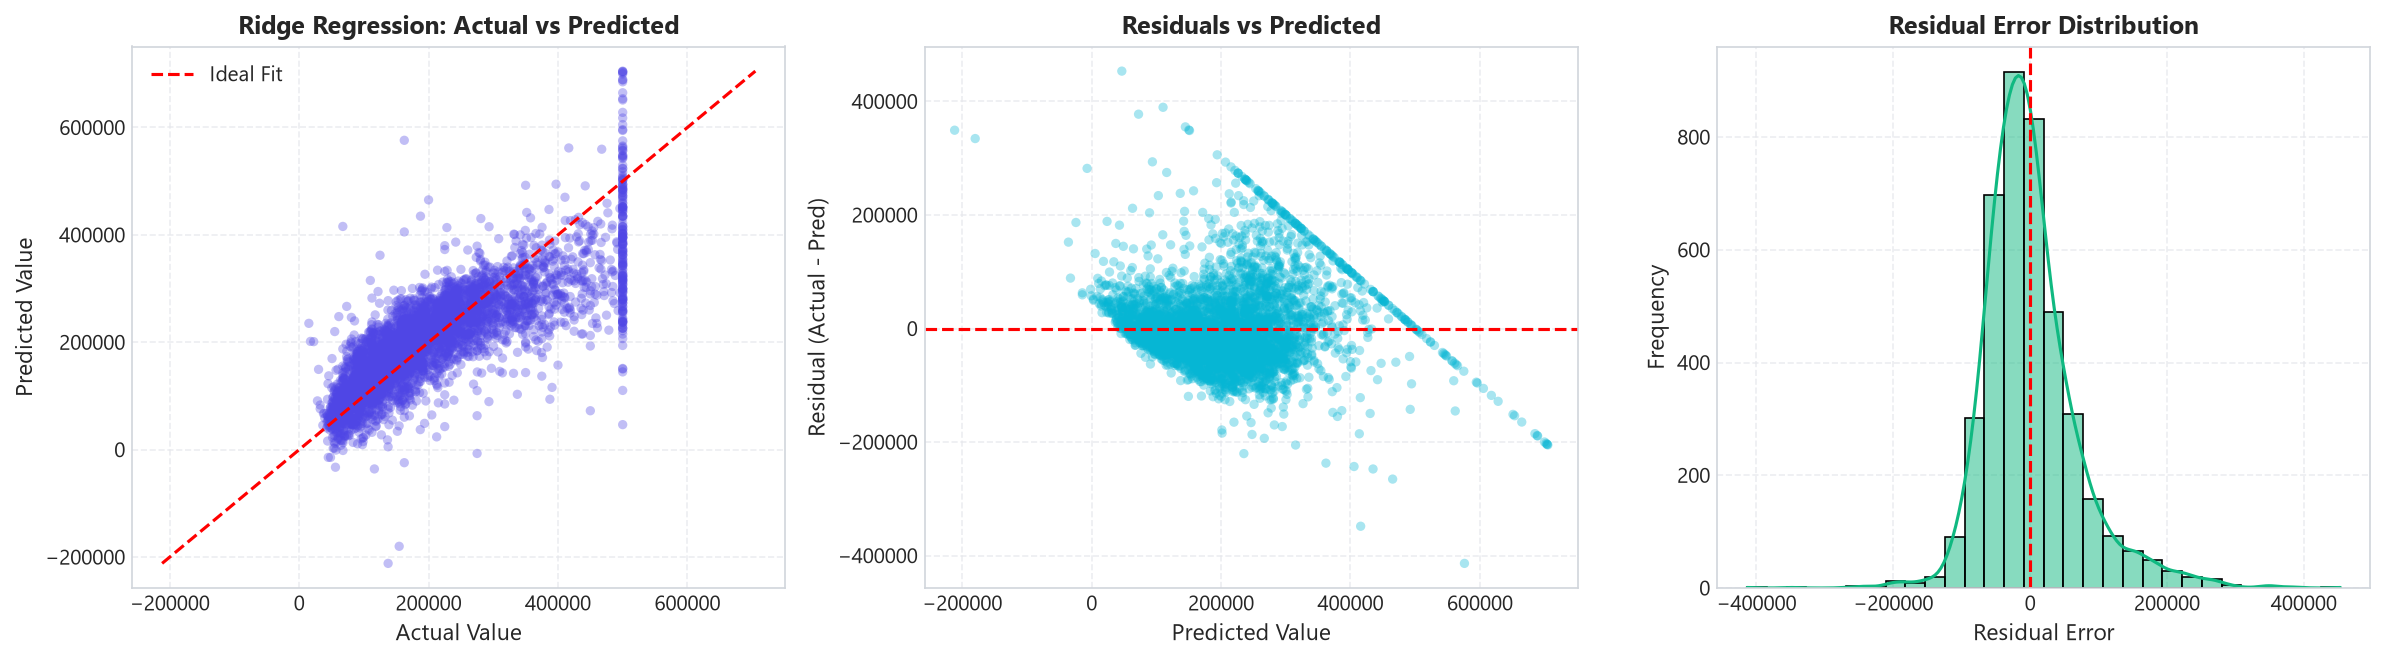

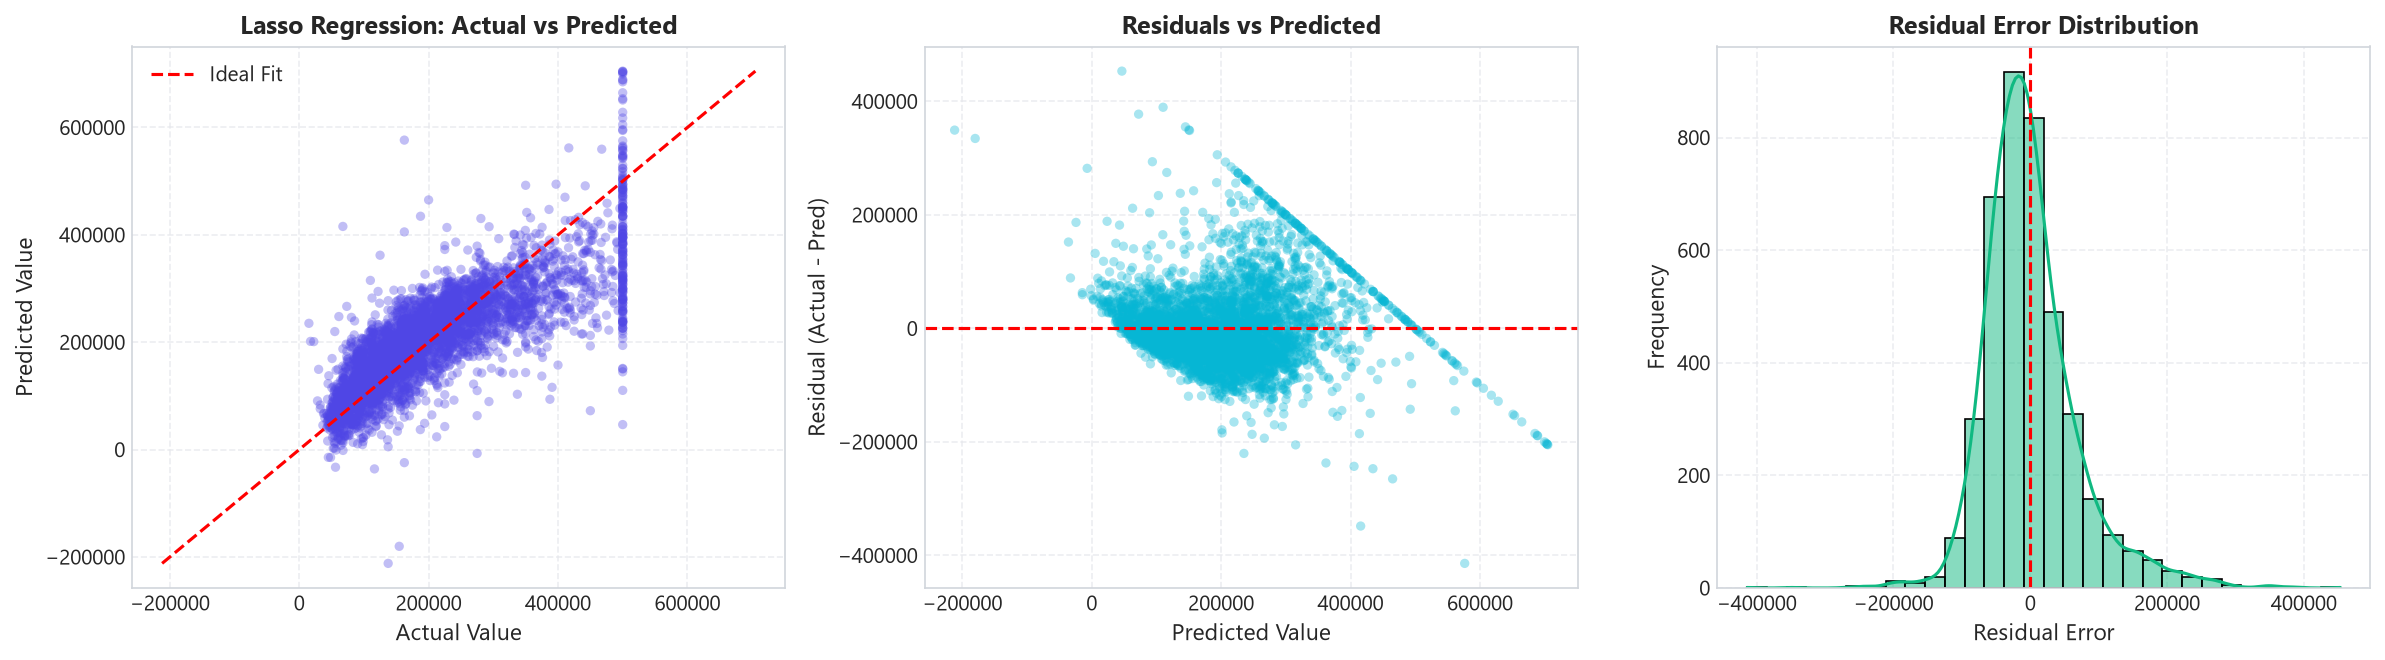

In [8]:
y_test_arr = y_test.to_numpy()
for name, y_pred in predictions.items():
    fig = plot_regression_diagnostics(
        y_true=y_test_arr,
        y_pred=y_pred,
        model_name=name.replace('_', ' ').title()
    )
    plt.show()


### 9. Model Comparison Visualizations

[WARNING] findfont: Failed to find font weight medium for Segoe UI, now using 400.


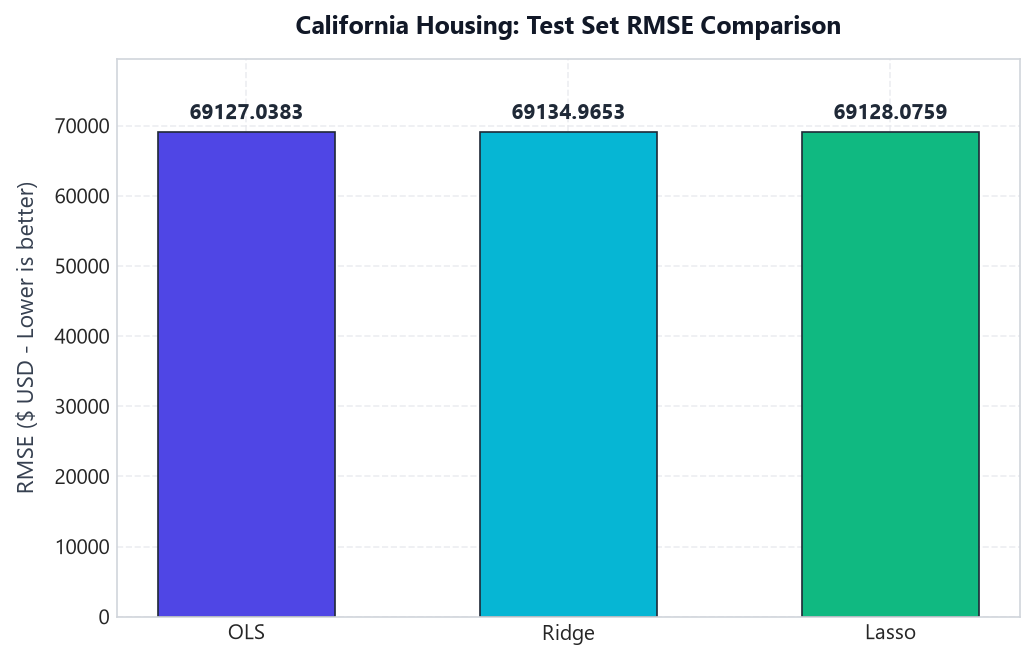

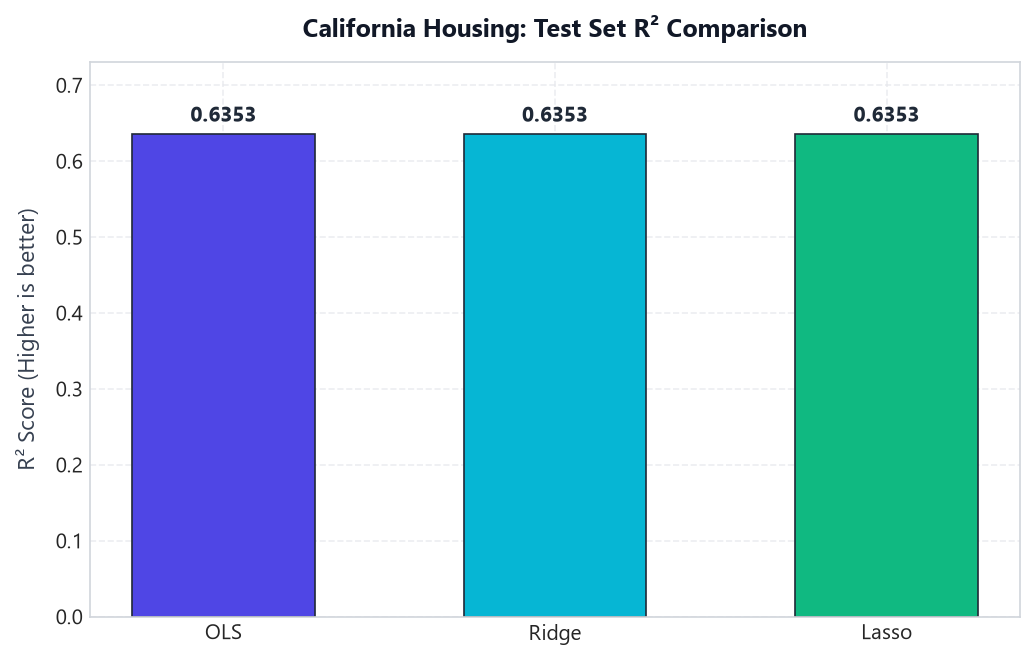

In [9]:
fig_rmse = plot_model_comparison(
    models_dict={
        'OLS': results['ols_linear_regression']['rmse'],
        'Ridge': results['ridge_regression']['rmse'],
        'Lasso': results['lasso_regression']['rmse']
    },
    metric_name='RMSE ($ USD - Lower is better)',
    title='California Housing: Test Set RMSE Comparison'
)
plt.show()

fig_r2 = plot_model_comparison(
    models_dict={
        'OLS': results['ols_linear_regression']['r2'],
        'Ridge': results['ridge_regression']['r2'],
        'Lasso': results['lasso_regression']['r2']
    },
    metric_name='R² Score (Higher is better)',
    title='California Housing: Test Set R² Comparison'
)
plt.show()


### 10. Reusable Real-World Prediction Inferences
We test the fitted pipeline on realistic district property configurations.


In [10]:
sample_properties = [
    {
        "description": "High-income coastal property in San Francisco Bay",
        "features": {
            "longitude": -122.25,
            "latitude": 37.85,
            "housing_median_age": 52.0,
            "total_rooms": 1274.0,
            "total_bedrooms": 235.0,
            "population": 558.0,
            "households": 219.0,
            "median_income": 8.0,
            "ocean_proximity": "NEAR BAY"
        }
    },
    {
        "description": "Modest inland property in Central Valley",
        "features": {
            "longitude": -119.80,
            "latitude": 36.75,
            "housing_median_age": 25.0,
            "total_rooms": 1500.0,
            "total_bedrooms": 300.0,
            "population": 800.0,
            "households": 280.0,
            "median_income": 2.5,
            "ocean_proximity": "INLAND"
        }
    }
]

for item in sample_properties:
    pred = predict_house_value(models['ridge_regression'], item['features'])
    print(f"Property: {item['description']}")
    print(f" -> Predicted Value: {pred['predicted_value_formatted']}")
    print()


Property: High-income coastal property in San Francisco Bay
 -> Predicted Value: $417,418.90

Property: Modest inland property in Central Valley
 -> Predicted Value: $91,209.20



### 11. Statistical & Engineering Takeaways
1. **Income Dominance**: `median_income` exhibits the strongest linear correlation (~0.69) with housing values.
2. **Regularization Performance**:
   - Ridge regression (`alpha=10.0` to `50.0`) stabilizes collinear geographic coefficients and yields robust generalization.
   - Lasso performs automated feature sparsity, zeroing out minor collinear parameters while preserving predictive power.
3. **Residual Insights**: Residual plots reveal slight heteroscedasticity for high-value properties due to the $500,001 artificial cap in census collection.
